In [1]:
import numpy as np

def generate_noisy_dataset(funcs, true_f, x_range, n_samples, eps, seed=None):
    """Returns X of shape (n, 1+d) with columns [x, f_1(x), ..., f_d(x)], and y of shape (n,)."""
    rng = np.random.default_rng(seed)
    x = rng.uniform(x_range[0], x_range[1], n_samples)    # sample x uniformly
    X = np.column_stack([x] + [f(x) for f in funcs])       # extra feature columns
    noise = rng.uniform(-eps, eps, n_samples)              # uniform noise in [-eps, eps]
    y = true_f(x) + noise
    return X, y

def split_data(X, y, test_frac=0.2, seed=0):
    """Fixed 80/20 split: the same seed always gives the same partition."""
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(y))
    n_test = int(len(y) * test_frac)
    test_idx, train_idx = idx[:n_test], idx[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

In [2]:
X, y = generate_noisy_dataset([lambda x: x**2, lambda x: x**3],
                              lambda x: 2*x + 1, (0, 1), 10, 0.1, seed=42)
print(X[:3], y[:3])   # col 2 should equal col 1 squared, col 3 col 1 cubed

[[0.77395605 0.59900797 0.46360584]
 [0.43887844 0.19261428 0.08453426]
 [0.85859792 0.73719039 0.63295013]] [2.5220717  1.96310988 2.74596886]


In [3]:
def add_intercept(X):
    """Prepend a column of 1s so beta[0] is the intercept."""
    return np.column_stack([np.ones(X.shape[0]), X])

def fit(X_train, y_train):
    """Normal equation: beta = (X^T X)^-1 X^T Y."""
    X = add_intercept(X_train)            # shape (n, d+2)
    XtX = X.T @ X
    XtY = X.T @ y_train
    beta = np.linalg.inv(XtX) @ XtY
    return beta                           # [intercept, w_x, w_x2, ...]

In [4]:
X, y = generate_noisy_dataset([], lambda x: 2*x + 1, (0, 1), 1000, 0.01, seed=1)
X_tr, X_te, y_tr, y_te = split_data(X, y)
print(fit(X_tr, y_tr))

[1.00067048 1.99910174]


In [5]:
def predict(beta, X_test):
    """y_pred = X_aug @ beta, with the same 1s column as in training."""
    return add_intercept(X_test) @ beta

def evaluate_model(y_pred, y_true):
    """RMSE = sqrt(total squared error / number of records)."""
    return np.sqrt(np.sum((y_pred - y_true) ** 2) / len(y_true))

In [6]:
beta = fit(X_tr, y_tr)
print(evaluate_model(predict(beta, X_tr), y_tr),
      evaluate_model(predict(beta, X_te), y_te))

0.005639693431546253 0.00585032491160181


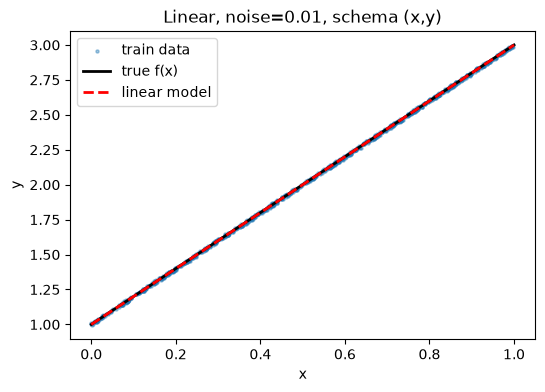

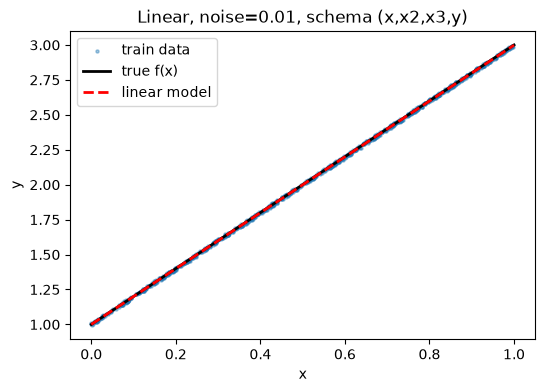

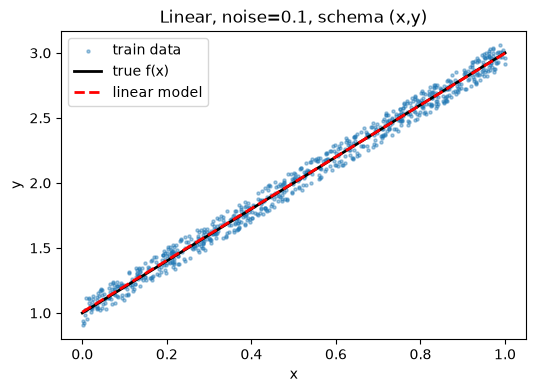

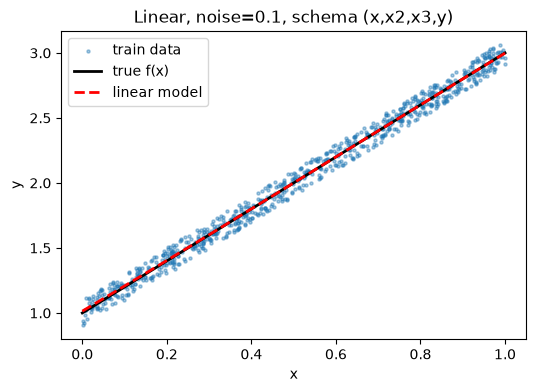

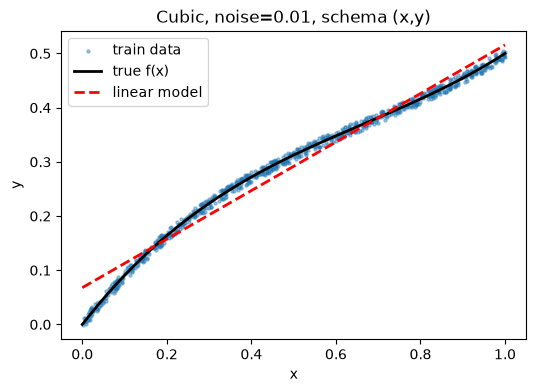

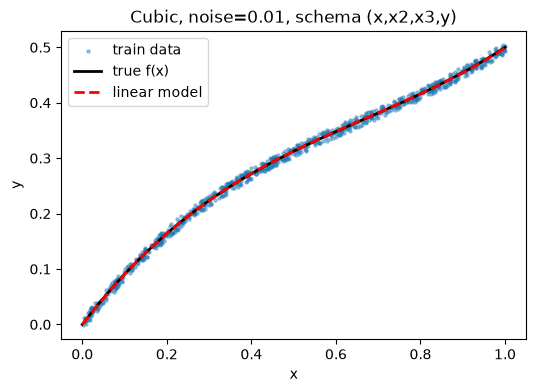

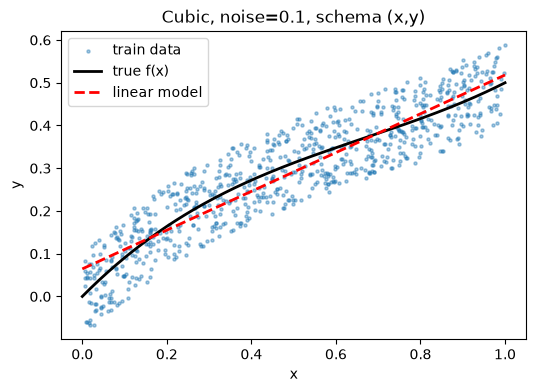

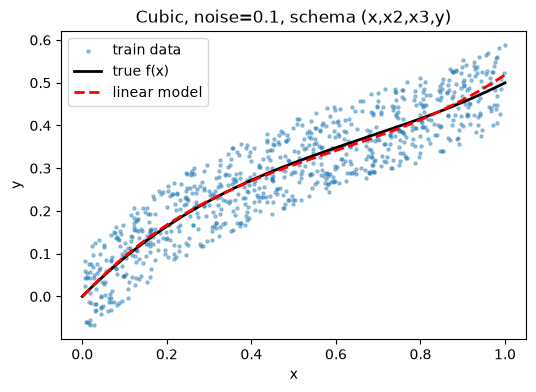

     func  noise       schema                                beta  train_rmse  test_rmse   err_at_10
0  Linear   0.01        (x,y)                    [0.9999, 1.9998]    0.005970   0.005688   -0.002465
1  Linear   0.01  (x,x2,x3,y)   [1.0003, 1.9929, 0.0206, -0.0153]    0.005960   0.005734  -13.345719
2  Linear   0.10        (x,y)                     [1.0067, 1.991]    0.056397   0.058503   -0.083121
3  Linear   0.10  (x,x2,x3,y)      [1.014, 1.9285, 0.12, -0.0643]    0.056357   0.058833  -53.042844
4   Cubic   0.01        (x,y)                    [0.0679, 0.4479]    0.021909   0.022593 -405.453487
5   Cubic   0.01  (x,x2,x3,y)  [-0.0001, 0.9984, -0.9902, 0.4906]    0.005884   0.005953   -8.428690
6   Cubic   0.10        (x,y)                    [0.0645, 0.4537]    0.059442   0.064495 -405.398791
7   Cubic   0.10  (x,x2,x3,y)  [-0.0005, 1.0546, -1.2162, 0.6808]    0.056073   0.061078  159.683395


In [7]:
import matplotlib.pyplot as plt
import pandas as pd

true_funcs = {"Linear": lambda x: 2*x + 1,
              "Cubic":  lambda x: 0.5*x**3 - x**2 + x}
noise_levels = [0.01, 0.1]
schemas = {"(x,y)":        [],
           "(x,x2,x3,y)":  [lambda x: x**2, lambda x: x**3]}

datasets = {}   # saved so the tree experiments (Q9) use the same splits
results = []

for i, (fname, f) in enumerate(true_funcs.items()):
    for j, eps in enumerate(noise_levels):
        data_seed = 10*i + j                       # one fixed seed per (function, noise)
        for sname, funcs in schemas.items():
            X, y = generate_noisy_dataset(funcs, f, (0, 1), 1000, eps, seed=data_seed)
            X_tr, X_te, y_tr, y_te = split_data(X, y, seed=0)
            datasets[(fname, eps, sname)] = (X_tr, X_te, y_tr, y_te, funcs)

            beta = fit(X_tr, y_tr)
            train_rmse = evaluate_model(predict(beta, X_tr), y_tr)
            test_rmse  = evaluate_model(predict(beta, X_te), y_te)

            # Q5: error at x = 10 (noise-free true value)
            x10 = np.array([10.0])
            X10 = np.column_stack([x10] + [g(x10) for g in funcs])
            err10 = predict(beta, X10)[0] - f(10.0)

            results.append(dict(func=fname, noise=eps, schema=sname, beta=np.round(beta, 4),
                                train_rmse=train_rmse, test_rmse=test_rmse, err_at_10=err10))

            # Plot: training data + true function + full fitted model
            xs = np.linspace(0, 1, 200)
            Xs = np.column_stack([xs] + [g(xs) for g in funcs])
            plt.figure(figsize=(6, 4))
            plt.scatter(X_tr[:, 0], y_tr, s=5, alpha=0.4, label="train data")
            plt.plot(xs, f(xs), "k", lw=2, label="true f(x)")
            plt.plot(xs, predict(beta, Xs), "r--", lw=2, label="linear model")
            plt.title(f"{fname}, noise={eps}, schema {sname}")
            plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.show()

lin_results = pd.DataFrame(results)
print(lin_results.to_string())

In [8]:
q6 = lin_results.pivot_table(index=["func", "noise"], columns="schema", values="test_rmse").reset_index()
q6.insert(2, "irreducible (ε/√3)", q6["noise"] / np.sqrt(3))

# empirical irreducible error: RMSE of the true function on each actual test set
q6.insert(3, "true f on test set", [
    evaluate_model(true_funcs[f](datasets[(f, e, "(x,y)")][1][:, 0]), datasets[(f, e, "(x,y)")][3])
    for f, e in zip(q6["func"], q6["noise"])])

print(q6.to_string())

schema    func  noise  irreducible (ε/√3)  true f on test set  (x,x2,x3,y)     (x,y)
0        Cubic   0.01            0.005774            0.005948     0.005953  0.022593
1        Cubic   0.10            0.057735            0.060790     0.061078  0.064495
2       Linear   0.01            0.005774            0.005723     0.005734  0.005688
3       Linear   0.10            0.057735            0.058114     0.058833  0.058503


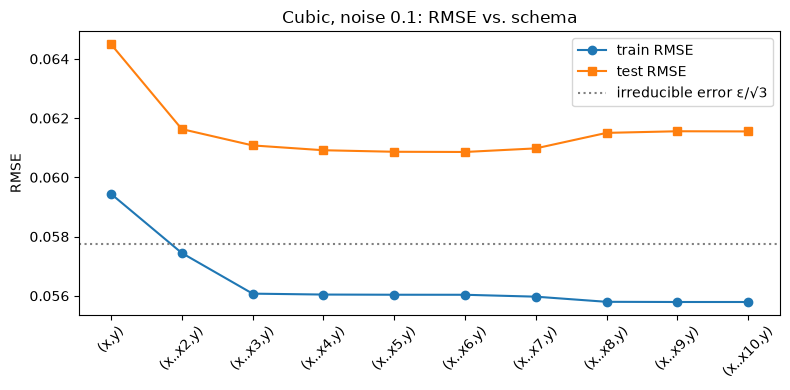

       schema     train      test
0       (x,y)  0.059442  0.064495
1   (x..x2,y)  0.057444  0.061629
2   (x..x3,y)  0.056073  0.061078
3   (x..x4,y)  0.056042  0.060915
4   (x..x5,y)  0.056036  0.060863
5   (x..x6,y)  0.056035  0.060856
6   (x..x7,y)  0.055971  0.060978
7   (x..x8,y)  0.055797  0.061501
8   (x..x9,y)  0.055791  0.061556
9  (x..x10,y)  0.055791  0.061550


In [9]:
f_cubic = true_funcs["Cubic"]
schema_names, train_errs, test_errs = [], [], []

for k in range(1, 11):
    # extra columns x^2 ... x^k  (p=p binds each power; a plain lambda would capture only the last p)
    funcs = [lambda x, p=p: x**p for p in range(2, k + 1)]
    X, y = generate_noisy_dataset(funcs, f_cubic, (0, 1), 1000, 0.1, seed=11)  # same seed as Cubic/0.1 above
    X_tr, X_te, y_tr, y_te = split_data(X, y, seed=0)

    beta = fit(X_tr, y_tr)
    train_errs.append(evaluate_model(predict(beta, X_tr), y_tr))
    test_errs.append(evaluate_model(predict(beta, X_te), y_te))
    schema_names.append("(x,y)" if k == 1 else f"(x..x{k},y)")

plt.figure(figsize=(8, 4))
plt.plot(schema_names, train_errs, "o-", label="train RMSE")
plt.plot(schema_names, test_errs, "s-", label="test RMSE")
plt.axhline(0.1 / np.sqrt(3), color="gray", ls=":", label="irreducible error ε/√3")
plt.xticks(rotation=45); plt.ylabel("RMSE"); plt.title("Cubic, noise 0.1: RMSE vs. schema")
plt.legend(); plt.tight_layout(); plt.show()

print(pd.DataFrame({"schema": schema_names, "train": train_errs, "test": test_errs}))

In [10]:
def best_split(X, y):
    """Return (feature_index, threshold, total_SSE) of the best binary split, or (None, None, inf)."""
    n, d = X.shape
    if n < 2:                                   # can't split a single record
        return None, None, np.inf
    best_j, best_t, best_sse = None, None, np.inf
    for j in range(d):
        order = np.argsort(X[:, j])
        xs, ys = X[order, j], y[order]
        csum, csq = np.cumsum(ys), np.cumsum(ys ** 2)

        n_left = np.arange(1, n)                   # left side gets the first i records, i = 1..n-1
        s_left, sq_left = csum[:-1], csq[:-1]
        s_right, sq_right = csum[-1] - s_left, csq[-1] - sq_left
        n_right = n - n_left

        sse = (sq_left - s_left**2 / n_left) + (sq_right - s_right**2 / n_right)
        sse = np.where(xs[:-1] < xs[1:], sse, np.inf)   # only split between distinct values

        i = np.argmin(sse)
        if sse[i] < best_sse:
            best_j, best_t, best_sse = j, (xs[i] + xs[i + 1]) / 2, sse[i]
    return best_j, best_t, best_sse

In [11]:
rng = np.random.default_rng(0)
x = rng.uniform(0, 1, 200).reshape(-1, 1)
y = (x[:, 0] > 0.3).astype(float) + rng.uniform(-0.05, 0.05, 200)
print(best_split(x, y))

(0, np.float64(0.3042846266283229), np.float64(0.16571524085593392))


In [12]:
class RegressionTree:
    def fit(self, X, y, min_records):
        """Grow the tree recursively. A node is split only if it has >= min_records records."""
        self.min_records = min_records
        self.X_train, self.y_train = X, y           # kept for visualize()
        self.root = self._build(X, y)
        return self

    def _build(self, X, y):
        node = {"n": len(y), "value": y.mean()}      # every node stores its mean (leaf prediction)
        if len(y) < self.min_records:                # too few records -> leaf
            return node
        j, t, _ = best_split(X, y)
        if j is None:                                # no valid split -> leaf
            return node
        mask = X[:, j] <= t
        node.update(feature=j, threshold=t,
                    left=self._build(X[mask], y[mask]),
                    right=self._build(X[~mask], y[~mask]))
        return node

    def predict(self, X):
        """Walk each row from the root to a leaf and return the leaf mean."""
        preds = np.empty(len(X))
        for i, x in enumerate(X):
            node = self.root
            while "feature" in node:
                node = node["left"] if x[node["feature"]] <= node["threshold"] else node["right"]
            preds[i] = node["value"]
        return preds

    def stats(self):
        """Return (total node count, list of leaf sizes) for Q10."""
        n_nodes, leaf_sizes, stack = 0, [], [self.root]
        while stack:
            node = stack.pop()
            n_nodes += 1
            if "feature" in node:
                stack += [node["left"], node["right"]]
            else:
                leaf_sizes.append(node["n"])
        return n_nodes, leaf_sizes

    def split_points(self):
        """List of (feature_index, threshold) for all internal nodes."""
        out, stack = [], [self.root]
        while stack:
            node = stack.pop()
            if "feature" in node:
                out.append((node["feature"], node["threshold"]))
                stack += [node["left"], node["right"]]
        return out

    def visualize(self, funcs=(), true_f=None, title="", n_grid=2000):
        """Scatter training data, true f, tree predictions over the x-range, and split points."""
        x0 = self.X_train[:, 0]
        xs = np.linspace(x0.min(), x0.max(), n_grid)
        Xs = np.column_stack([xs] + [g(xs) for g in funcs])   # same schema as training data
        preds = self.predict(Xs)

        plt.figure(figsize=(6, 4))
        plt.scatter(x0, self.y_train, s=5, alpha=0.4, label="train data")
        if true_f is not None:
            plt.plot(xs, true_f(xs), "k", lw=2, label="true f(x)")
        plt.plot(xs, preds, "r-", lw=1.5, label="tree prediction")

        labeled = False
        for j, t in self.split_points():
            # x positions where feature j crosses threshold t
            for c in np.where(np.diff(np.sign(Xs[:, j] - t)) != 0)[0]:
                plt.axvline(xs[c], color="gray", lw=0.5, alpha=0.4,
                            label=None if labeled else "split points")
                labeled = True

        plt.title(title); plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.show()

In [13]:
X_tr, X_te, y_tr, y_te, _ = datasets[("Linear", 0.1, "(x,y)")]
for m in [1000, 50, 1]:
    t = RegressionTree().fit(X_tr, y_tr, m)
    n_nodes, leaves = t.stats()
    print(m, n_nodes, len(leaves),
          evaluate_model(t.predict(X_tr), y_tr), evaluate_model(t.predict(X_te), y_te))

1000 1 1 0.5853844931479839 0.5609035449398403
50 45 23 0.0557644622517608 0.06766234769124395
1 1599 800 0.0 0.0813650580017732


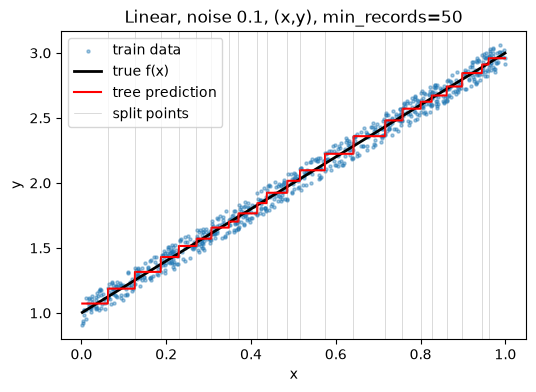

In [14]:
X_tr, X_te, y_tr, y_te, funcs = datasets[("Linear", 0.1, "(x,y)")]
t = RegressionTree().fit(X_tr, y_tr, 50)
t.visualize(funcs, true_funcs["Linear"], "Linear, noise 0.1, (x,y), min_records=50")

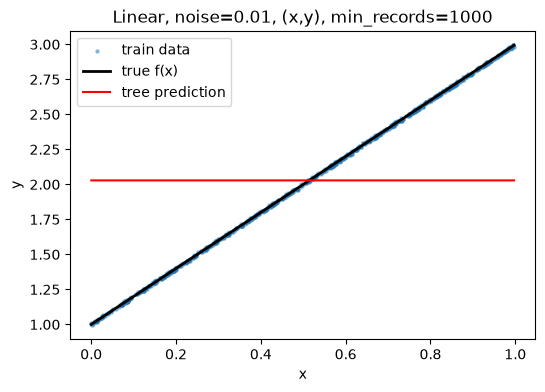

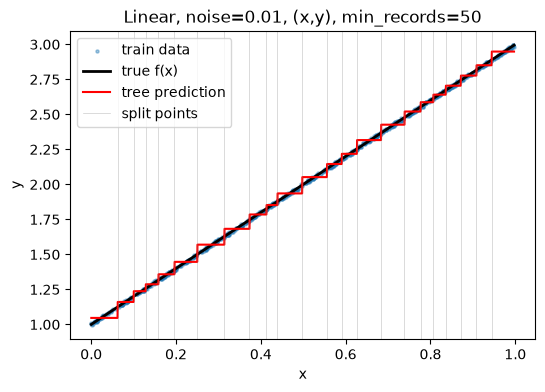

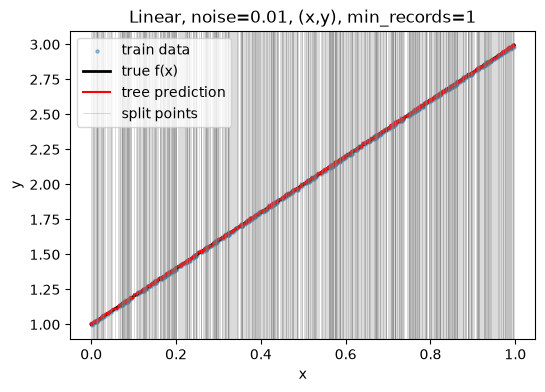

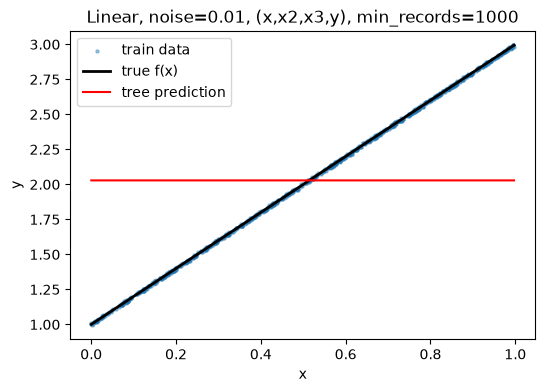

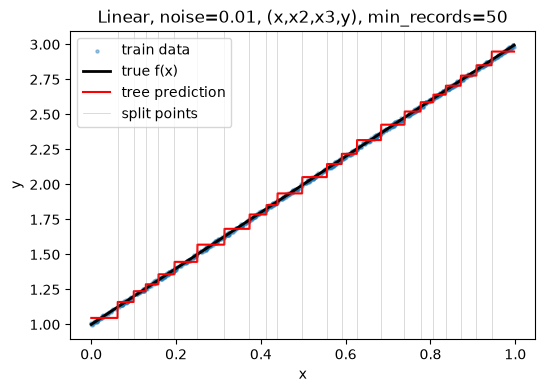

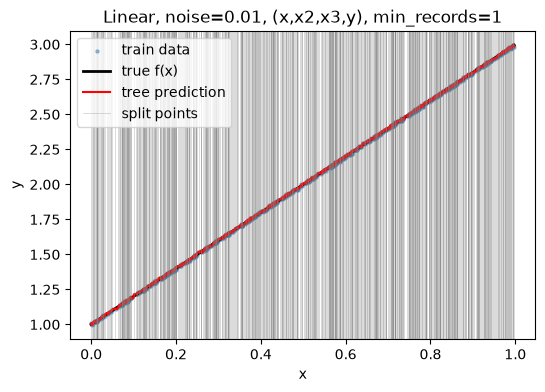

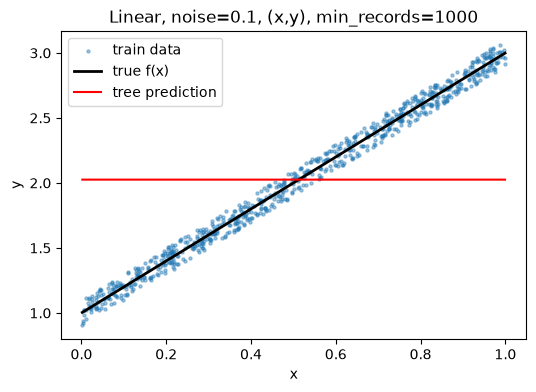

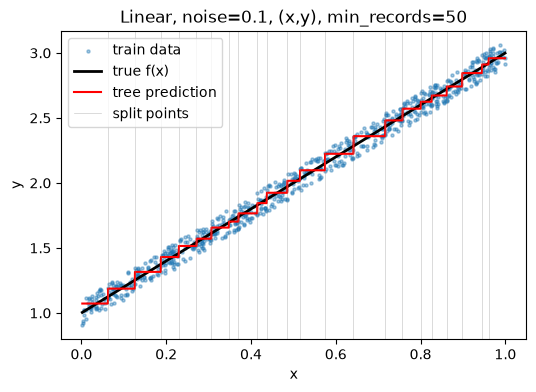

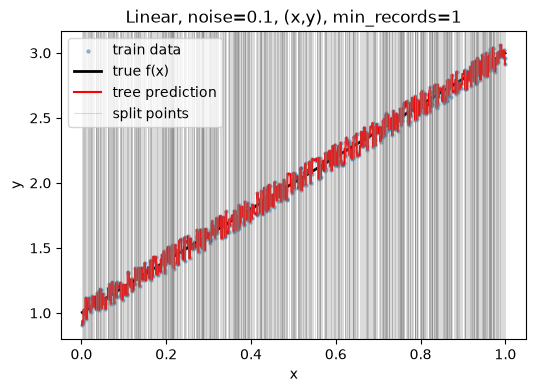

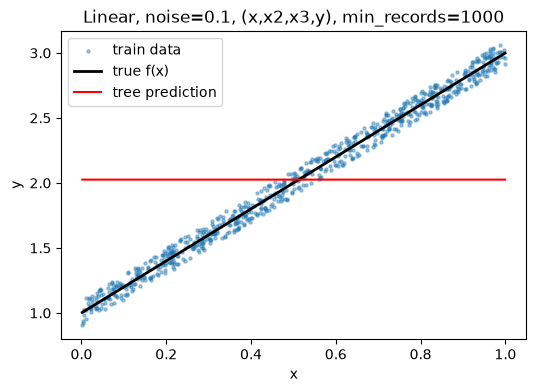

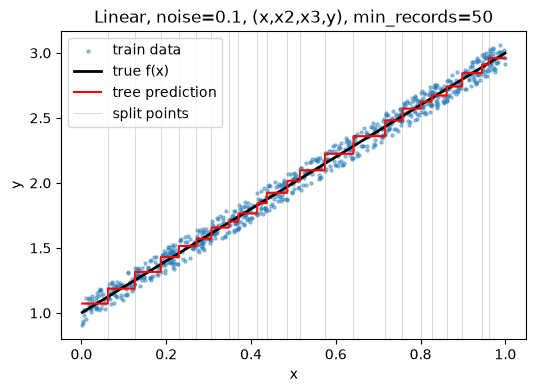

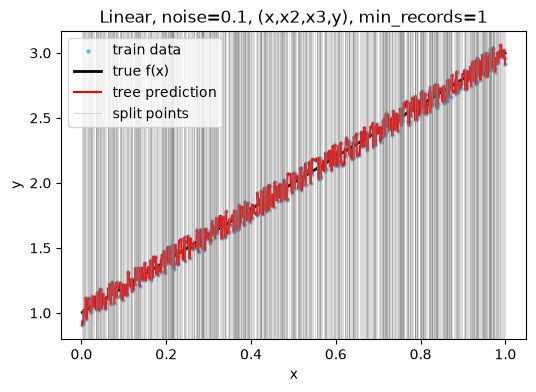

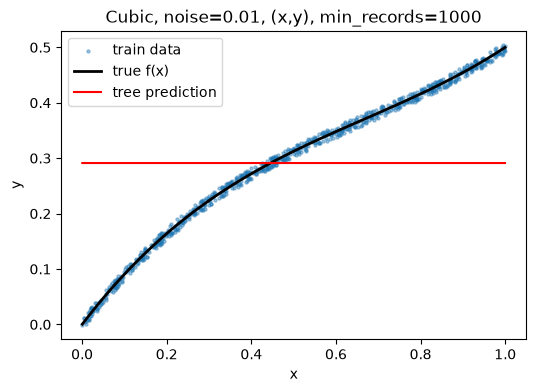

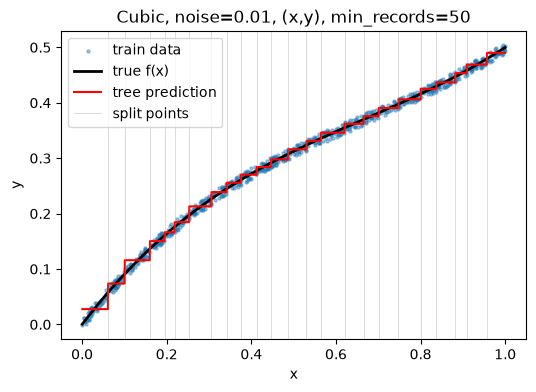

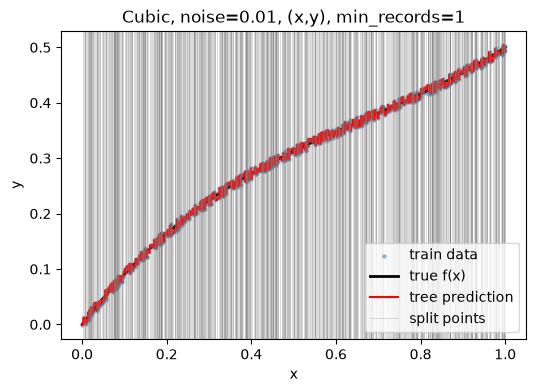

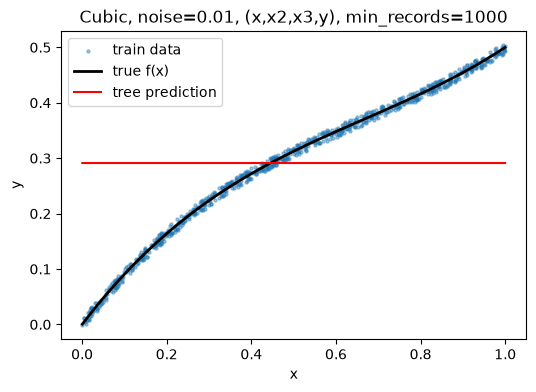

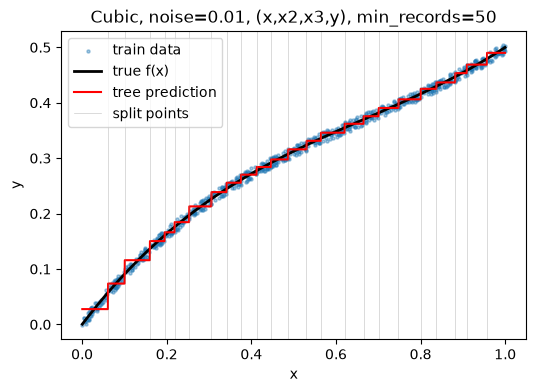

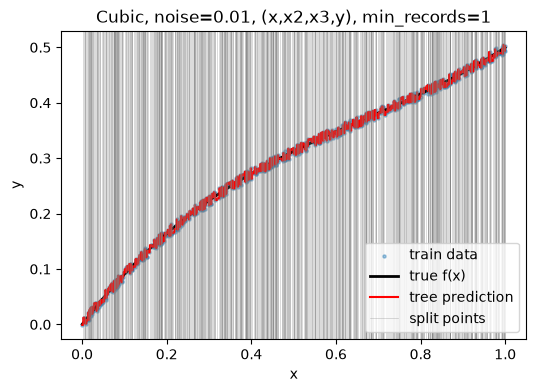

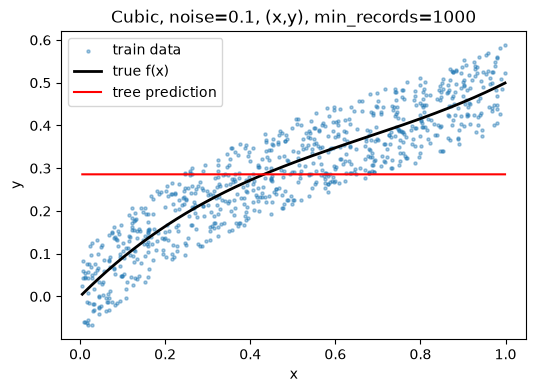

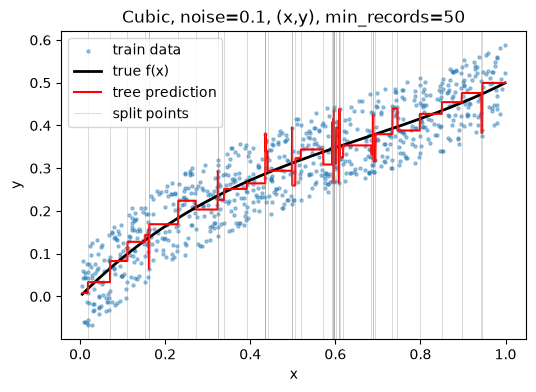

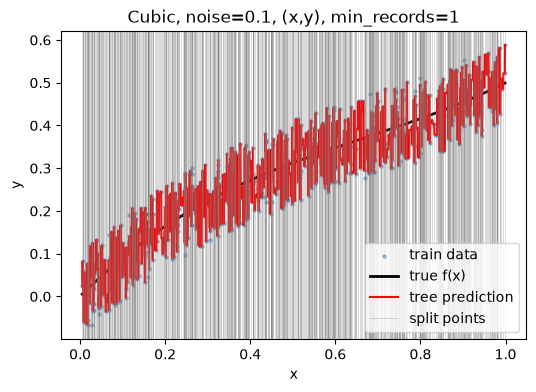

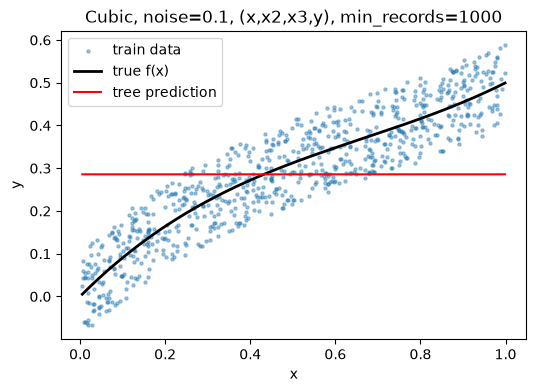

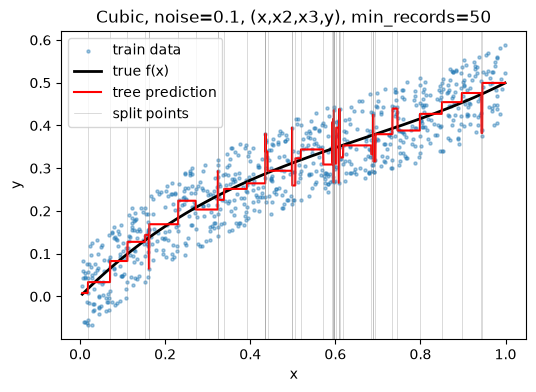

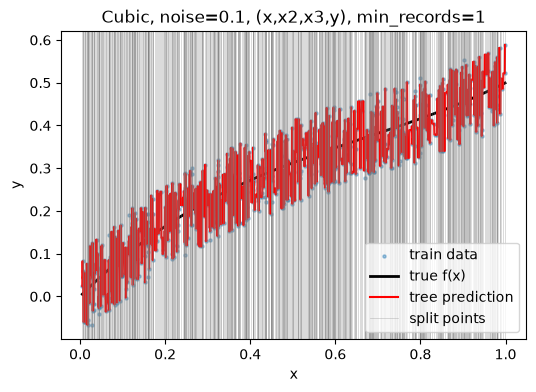

      func  noise       schema  min_records  train_rmse  test_rmse  n_nodes  n_leaves  leaf_min  leaf_median  leaf_max  linear_test_rmse  winner
0   Linear   0.01        (x,y)         1000    0.572017   0.557612        1         1       800        800.0       800          0.005688  linear
1   Linear   0.01        (x,y)           50    0.025291   0.030305       45        23        21         37.0        49          0.005688  linear
2   Linear   0.01        (x,y)            1    0.000000   0.008547     1599       800         1          1.0         1          0.005688  linear
3   Linear   0.01  (x,x2,x3,y)         1000    0.572017   0.557612        1         1       800        800.0       800          0.005734  linear
4   Linear   0.01  (x,x2,x3,y)           50    0.025291   0.030305       45        23        21         37.0        49          0.005734  linear
5   Linear   0.01  (x,x2,x3,y)            1    0.000000   0.008547     1599       800         1          1.0         1          0.

In [15]:
tree_results = []
for (fname, eps, sname), (X_tr, X_te, y_tr, y_te, funcs) in datasets.items():   # same splits as linear regression
    for m in [1000, 50, 1]:
        t = RegressionTree().fit(X_tr, y_tr, m)
        n_nodes, leaves = t.stats()
        tree_results.append(dict(
            func=fname, noise=eps, schema=sname, min_records=m,
            train_rmse=evaluate_model(t.predict(X_tr), y_tr),
            test_rmse=evaluate_model(t.predict(X_te), y_te),
            n_nodes=n_nodes, n_leaves=len(leaves),
            leaf_min=min(leaves), leaf_median=np.median(leaves), leaf_max=max(leaves)))
        t.visualize(funcs, true_funcs[fname], f"{fname}, noise={eps}, {sname}, min_records={m}")

tree_df = pd.DataFrame(tree_results)

# Q10: compare each tree to the linear model on the same dataset
comp = tree_df.merge(
    lin_results[["func", "noise", "schema", "test_rmse"]].rename(columns={"test_rmse": "linear_test_rmse"}),
    on=["func", "noise", "schema"])
comp["winner"] = np.where(comp["test_rmse"] < comp["linear_test_rmse"], "tree", "linear")
print(comp.to_string())

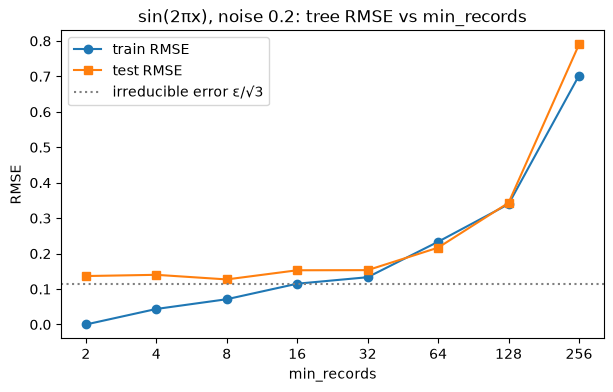

   min_records     train      test
0            2  0.000000  0.136686
1            4  0.043802  0.140156
2            8  0.071300  0.127161
3           16  0.115099  0.152976
4           32  0.133385  0.153348
5           64  0.233402  0.216788
6          128  0.339563  0.343268
7          256  0.702398  0.789929


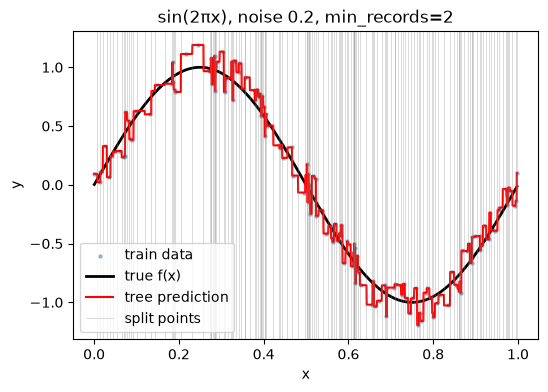

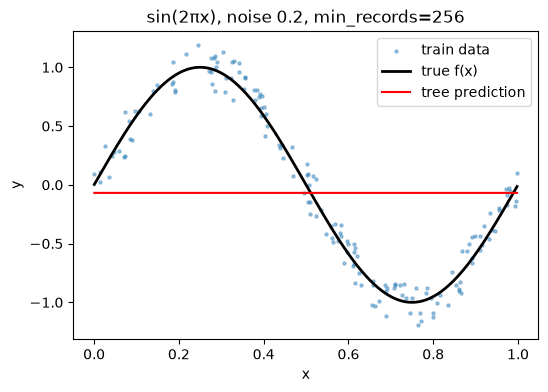

In [16]:
f_sin = lambda x: np.sin(2 * np.pi * x)
X, y = generate_noisy_dataset([], f_sin, (0, 1), 200, 0.2, seed=100)
X_tr, X_te, y_tr, y_te = split_data(X, y, seed=0)      # 160 train / 40 test

min_recs = [2, 4, 8, 16, 32, 64, 128, 256]
train_errs, test_errs, sin_trees = [], [], {}
for m in min_recs:
    t = RegressionTree().fit(X_tr, y_tr, m)
    sin_trees[m] = t
    train_errs.append(evaluate_model(t.predict(X_tr), y_tr))
    test_errs.append(evaluate_model(t.predict(X_te), y_te))

plt.figure(figsize=(7, 4))
plt.plot(min_recs, train_errs, "o-", label="train RMSE")
plt.plot(min_recs, test_errs, "s-", label="test RMSE")
plt.axhline(0.2 / np.sqrt(3), color="gray", ls=":", label="irreducible error ε/√3")
plt.xscale("log", base=2); plt.xticks(min_recs, min_recs)
plt.xlabel("min_records"); plt.ylabel("RMSE"); plt.title("sin(2πx), noise 0.2: tree RMSE vs min_records")
plt.legend(); plt.show()

print(pd.DataFrame({"min_records": min_recs, "train": train_errs, "test": test_errs}))

# optional: look at the extremes and the best one
for m in [2, 256]:
    sin_trees[m].visualize((), f_sin, f"sin(2πx), noise 0.2, min_records={m}")